# Accessing Copernicus Marine data with the Copernicus Marine Toolbox

This notebook demonstrates how to download a subset of Copernicus Marine data using the current **Copernicus Marine Toolbox** Python API.

The Copernicus Marine Toolbox provides the current programmatic interface for exploring catalogue metadata, subsetting datasets, downloading original files, and accessing datasets remotely.

Useful resources:
- [Copernicus Marine Data Store](https://data.marine.copernicus.eu/products)
- [Copernicus Marine Toolbox – Introduction](https://help.marine.copernicus.eu/en/articles/7949409-copernicus-marine-toolbox-introduction)
- [Copernicus Marine Toolbox – Installation](https://help.marine.copernicus.eu/en/articles/7970514-copernicus-marine-toolbox-installation)


## 1. Copernicus Marine Toolbox

The Copernicus Marine Toolbox is available in the EOxHub kernel environment and provides the Python interface used in this notebook to access Copernicus Marine data.

The installed version can be checked with:

In [1]:
import copernicusmarine

print(f"Copernicus Marine Toolbox version: {copernicusmarine.__version__}")


Copernicus Marine Toolbox version: 2.5.0


## 2. Authentication

The Copernicus Marine Toolbox requires a Copernicus Marine account for data access. Credentials should **not** be written directly into the notebook.

For automated workflows, the Toolbox supports the environment variables `COPERNICUSMARINE_SERVICE_USERNAME` and `COPERNICUSMARINE_SERVICE_PASSWORD`. These can be configured by the EOxHub Workspaces or by the user.

If credentials are already configured in the EOxHub Workspaces, the following cells can be used to check whether the expected variables are available without displaying their values.

In [2]:
import os

username_configured = bool(os.environ.get("COPERNICUSMARINE_SERVICE_USERNAME"))
password_configured = bool(os.environ.get("COPERNICUSMARINE_SERVICE_PASSWORD"))

print(f"Username configured: {username_configured}")
print(f"Password configured: {password_configured}")


Username configured: False
Password configured: False


If the credentials are not available as environment variables, they can also be configured with the Toolbox's `login` functionality. See the official [credentials configuration documentation](https://help.marine.copernicus.eu/en/articles/7949409-copernicus-marine-toolbox-introduction) for the available methods.

## 3. Explore the Copernicus Marine catalogue

The Toolbox provides the `describe()` function to search the catalogue and retrieve metadata for products, datasets and variables. This is useful because dataset IDs can change as products evolve, allowing the current dataset to be identified directly from the catalogue.

In [3]:
catalogue = copernicusmarine.describe(
    contains=["GLOBAL_ANALYSISFORECAST_PHY_001_024"]
)

print(type(catalogue))


Fetching catalogue 1: 100%|██████████| 2/2 [00:11<00:00,  5.97s/it]  


<class 'copernicusmarine.catalogue_parser.models.CopernicusMarineCatalogue'>


The current Copernicus Marine product catalogue contains the **Global Ocean Physics Analysis and Forecast** product under `GLOBAL_ANALYSISFORECAST_PHY_001_024`. The product currently provides hourly, daily and monthly datasets. The product page should be consulted when selecting the dataset and variable needed for a particular request.

In [4]:
# Display a compact representation of the catalogue response.
# The exact structure can change as the catalogue evolves.
catalogue.model_dump().keys()


dict_keys(['products'])

## 4. Select the dataset and subset

The request retrieves the eastward ocean current (`uo`) for a region around the Black Sea, for a specified time period and near-surface depth.

The request is performed using the Copernicus Marine Toolbox `subset()` API.

The current product page lists the hourly dataset as `cmems_mod_glo_phy_anfc_0.083deg_PT1H-m`. This dataset provides the ocean current data used for the request.


In [5]:
dataset_id = "cmems_mod_glo_phy_anfc_0.083deg_PT1H-m"
variable = "uo"

longitude_min = 28.5
longitude_max = 32.5
latitude_min = 42.5
latitude_max = 46.0

start_datetime = "2022-06-01 00:00:00"
end_datetime = "2022-06-01 01:00:00"

minimum_depth = 0.494024
maximum_depth = 0.494026


**Note on the dates:** The current hourly dataset listed on the product page starts on 1 June 2022, so the example dates use a period currently covered by the dataset. Check the product page and `describe()` output when selecting a different time period.


## 5. Download the subset

The `subset()` function downloads only the requested part of the dataset. For gridded datasets, NetCDF is the default output format.

The variable, spatial extent, time range and depth range are specified directly as Python arguments, allowing the required subset of the dataset to be downloaded efficiently.

The `skip_existing=True` option prevents the Toolbox from downloading the same subset again when the output file already exists.

In [6]:
import getpass

username = getpass.getpass("Copernicus Marine username: ")
password = getpass.getpass("Copernicus Marine password: ")

output_directory = "."

response = copernicusmarine.subset(
    dataset_id=dataset_id,
    variables=[variable],
    start_datetime=start_datetime,
    end_datetime=end_datetime,
    minimum_longitude=longitude_min,
    maximum_longitude=longitude_max,
    minimum_latitude=latitude_min,
    maximum_latitude=latitude_max,
    minimum_depth=minimum_depth,
    maximum_depth=maximum_depth,
    output_directory=output_directory,
    skip_existing=True,
    username=username,
    password=password,
)

response

Copernicus Marine username:  ········
Copernicus Marine password:  ········


INFO - 2026-10-04T16:17:23Z - Selected dataset version: "202406"
INFO - 2026-10-04T16:17:23Z - Selected dataset part: "default"
WARNING - 2026-10-04T16:17:23Z - Some of your subset selection [0.494024, 0.494026] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 0.49402499198913574]
INFO - 2026-10-04T16:17:24Z - Total size of the download: 30.52 KB.


ResponseSubset(file_path=PosixPath('cmems_mod_glo_phy_anfc_0.083deg_PT1H-m_uo_28.50E-32.50E_42.50N-46.00N_0.49m_2022-06-01.nc'), output_directory=PosixPath('.'), filename='cmems_mod_glo_phy_anfc_0.083deg_PT1H-m_uo_28.50E-32.50E_42.50N-46.00N_0.49m_2022-06-01.nc', file_size=0.02980916030534351, data_transfer_size=16.00879389312977, variables=['uo'], coordinates_extent=[GeographicalExtent(minimum=28.5, maximum=32.5, unit='degrees_east', coordinate_id='longitude'), GeographicalExtent(minimum=42.5, maximum=46.0, unit='degrees_north', coordinate_id='latitude'), TimeExtent(minimum='2022-06-01T00:00:00+00:00', maximum='2022-06-01T01:00:00+00:00', unit='iso8601', coordinate_id='time'), GeographicalExtent(minimum=0.49402499198913574, maximum=0.49402499198913574, unit='m', coordinate_id='depth')], status='000', message='The request was successful.', file_status=<FileStatus.IGNORED: 'IGNORED'>, file_names=None)

## 6. Open the downloaded NetCDF file

The returned response contains information about the generated output. We can use `xarray` to inspect the downloaded NetCDF dataset.

In [7]:
import xarray as xr

output_file = response[0].file_path if isinstance(response, list) else response.file_path
print(output_file)

ds = xr.open_dataset(output_file)
ds

cmems_mod_glo_phy_anfc_0.083deg_PT1H-m_uo_28.50E-32.50E_42.50N-46.00N_0.49m_2022-06-01.nc


<xarray.Dataset> Size: 17kB
Dimensions:    (time: 2, depth: 1, latitude: 43, longitude: 49)
Coordinates:
  * time       (time) datetime64[ns] 16B 2022-06-01 2022-06-01T01:00:00
  * depth      (depth) float32 4B 0.494
  * latitude   (latitude) float32 172B 42.5 42.58 42.67 ... 45.83 45.92 46.0
  * longitude  (longitude) float32 196B 28.5 28.58 28.67 ... 32.33 32.42 32.5
Data variables:
    uo         (time, depth, latitude, longitude) float32 17kB ...
Attributes:
    Conventions:               CF-1.8
    area:                      Global
    contact:                   https://marine.copernicus.eu/contact
    credit:                    E.U. Copernicus Marine Service Information (CM...
    institution:               Mercator Ocean International
    licence:                   http://marine.copernicus.eu/services-portfolio...
    producer:                  CMEMS - Global Monitoring and Forecasting Centre
    references:                http://marine.copernicus.eu
    source:                    MOI GLO12
    title:                     hourly mean fields from Global Ocean Physics A...
    copernicusmarine_version:  2.5.0

## 7. Inspect the downloaded variable


In [8]:
ds[variable]


<xarray.DataArray 'uo' (time: 2, depth: 1, latitude: 43, longitude: 49)> Size: 17kB
[4214 values with dtype=float32]
Coordinates:
  * time       (time) datetime64[ns] 16B 2022-06-01 2022-06-01T01:00:00
  * depth      (depth) float32 4B 0.494
  * latitude   (latitude) float32 172B 42.5 42.58 42.67 ... 45.83 45.92 46.0
  * longitude  (longitude) float32 196B 28.5 28.58 28.67 ... 32.33 32.42 32.5
Attributes:
    cell_methods:   area: mean
    long_name:      Eastward surface velocity
    standard_name:  eastward_sea_water_velocity
    unit_long:      Meters per second
    units:          m s-1
    valid_max:      10.0
    valid_min:      -10.0

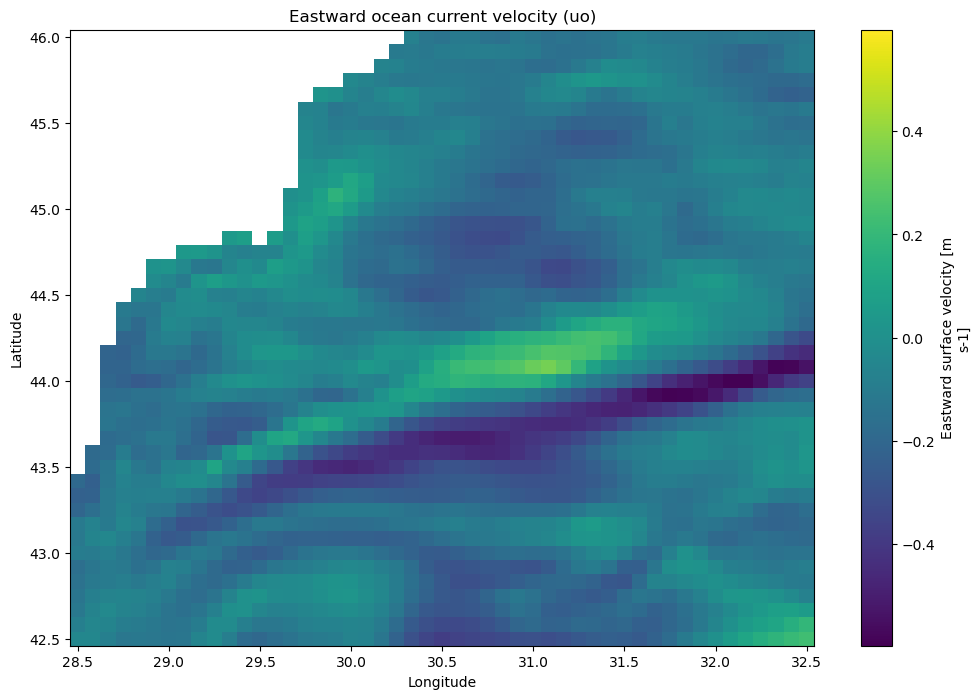

In [9]:
import matplotlib.pyplot as plt

ds[variable].isel(time=0, depth=0).plot.imshow(
    figsize=(12, 8),
    cmap="viridis"
)

plt.title("Eastward ocean current velocity (uo)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

## Summary

The Copernicus Marine Toolbox provides the tools used to access and process Copernicus Marine data:

* `copernicusmarine.describe()` can be used to explore the current catalogue and identify datasets and variables.
* `copernicusmarine.subset()` downloads only the requested spatial, temporal, depth and variable subset.
* The downloaded NetCDF data can then be processed with standard Python tools such as `xarray`.

This workflow follows the current Copernicus Marine Toolbox documentation and provides a direct way to access and work with the required ocean data.
